# Banknote Authentication Analysis

**Benjamin Dwomoh** · Portfolio project developed from MSc Data Analytics coursework

Classify the supplied binary labels and explore whether numerical features show distinct unsupervised groups.

This portfolio edition revises my submitted coursework for reproducibility and clearer interpretation.

Run the notebook from this repository folder. Place the dataset in `data/` as described in `data/README.md`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.5)})
DATA_PATH = Path("data") / 'bill_authentication.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place the dataset at {DATA_PATH.resolve()}; see data/README.md")

## Load and clean

Use the four numerical image-derived features supplied for coursework. Remove exact duplicates before splitting to reduce duplicate overlap between train and test.

In [3]:
bd = pd.read_csv(DATA_PATH)
display(bd.head())

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
bd.columns = bd.columns.str.strip().str.lower()
print(bd.shape)
print(bd.info())
print(bd.isna().sum())
print(bd.duplicated().sum())
print(bd.describe())

(1372, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64
24
          variance     skewness     curtosis      entropy        class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1.708200    -1.574975    -2.413450     0.000000
50%       0.496180     2.319650     0.61663

In [5]:
bd = bd.drop_duplicates().dropna().copy()
numeric_cols = ['variance', 'skewness', 'curtosis', 'entropy']
bd[numeric_cols] = bd[numeric_cols].apply(pd.to_numeric, errors='raise')
bd['class'] = bd['class'].astype(int)

assert bd['class'].isin([0, 1]).all()
assert not bd.isna().any().any()
print(bd.shape)
print(bd['class'].value_counts())

(1348, 5)
class
0    738
1    610
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import tree

## Fit a Decision Tree

Use a stratified 80/20 split and the original max_depth=4 and min_samples_leaf=5 settings. Class labels remain 0 and 1 because the supplied CSV does not define their meaning.

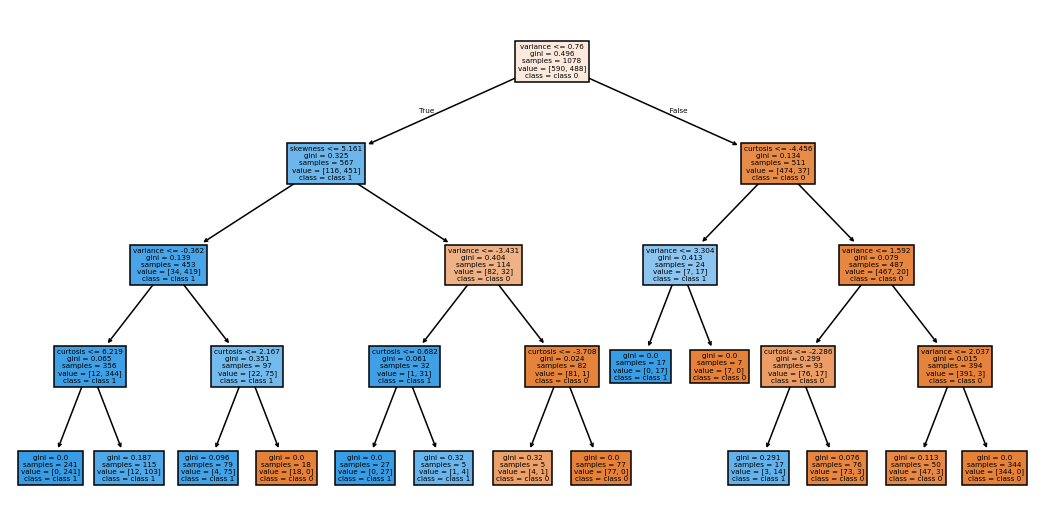

In [7]:
X=bd[['variance', 'skewness', 'curtosis', 'entropy']]
y=bd['class']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
y_prob = tree.predict_proba(X_test)[:, 1]
 
plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=X.columns, class_names=['class 0', 'class 1'], filled=True)
plt.show()

## Evaluate classification

Assess the same held-out labels throughout: accuracy, positive-class precision, recall, F1, confusion matrix and ROC-AUC.

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, RocCurveDisplay

In [9]:
metrics = pd.Series({
    "accuracy": accuracy_score(y_test, y_pred),
    "precision_class_1": precision_score(y_test, y_pred),
    "recall_class_1": recall_score(y_test, y_pred),
    "F1-score_class_1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob)
})
display(metrics.to_frame("test_result"))
print(classification_report(y_test, y_pred, target_names=["class 0", "class 1"]))

              precision    recall  f1-score   support

     class 0       1.00      0.96      0.98       148
     class 1       0.95      1.00      0.98       122

    accuracy                           0.98       270
   macro avg       0.98      0.98      0.98       270
weighted avg       0.98      0.98      0.98       270



,test_result
accuracy,0.977778
precision_class_1,0.953125
recall_class_1,1.000000
F1-score_class_1,0.976000
roc_auc,0.993216


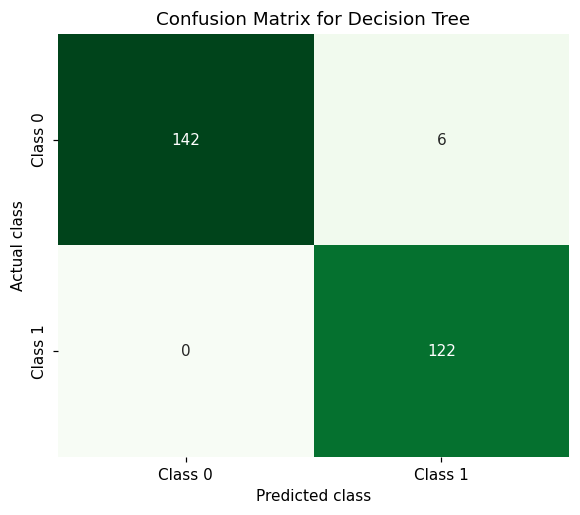

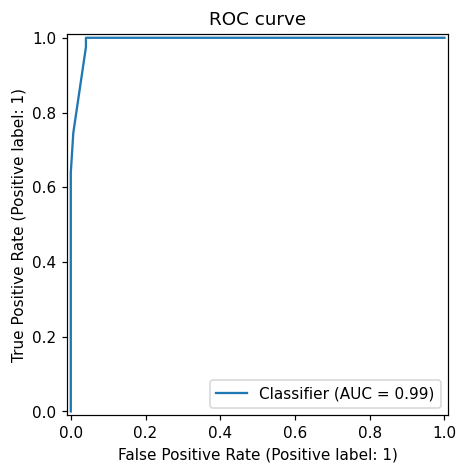

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Class 0", "Class 1"],
            yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix for Decision Tree")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve")
plt.show()

## Explore unsupervised clusters

Standardise the four features and compare k=2 through k=6. This exploratory clustering uses the full feature dataset separately from supervised model evaluation.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [12]:
X_cluster = bd[['variance', 'skewness', 'curtosis', 'entropy']] 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(bd[['variance', 'skewness', 'curtosis', 'entropy']])
 
k_values = range(2, 7)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

selection_results = pd.DataFrame({
    'K': list(k_values),
    'Inertia': inertias,
    'Silhouette': silhouette_scores
})
print(selection_results.round(4))

   K    Inertia  Silhouette
0  2  3399.6912      0.3281
1  3  2381.3141      0.3294
2  4  1877.1753      0.3236
3  5  1494.6305      0.3487
4  6  1304.2612      0.3298


Highest silhouette score occurs at K = 5


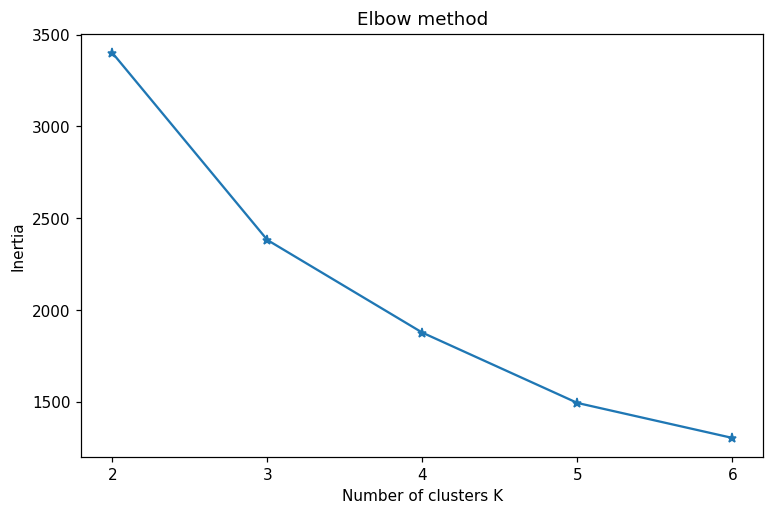

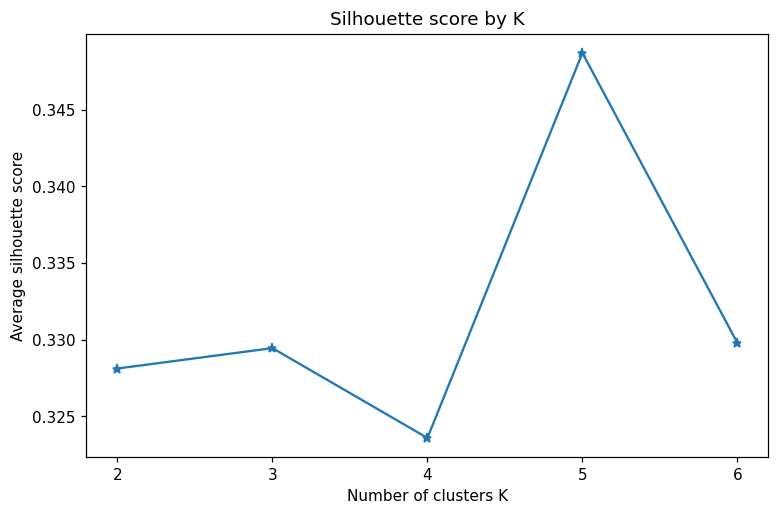

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker='*')
plt.xticks(list(k_values))
plt.xlabel('Number of clusters K')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker='*')
plt.xticks(list(k_values))
plt.xlabel('Number of clusters K')
plt.ylabel('Average silhouette score')
plt.title('Silhouette score by K')
plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print('Highest silhouette score occurs at K =', best_k)

class,0,1,All
cluster,,,
0,329,8,337
1,60,71,131
2,47,179,226
3,254,68,322
4,48,284,332
All,738,610,1348


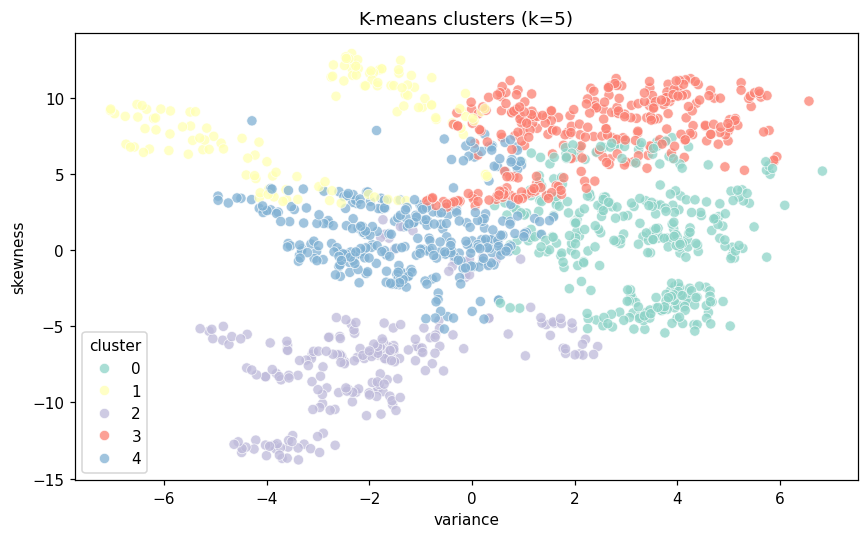

In [14]:
kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=42)
bd_clustered = bd.copy()
bd_clustered["cluster"] = kmeans.fit_predict(X_scaled)

display(pd.crosstab(bd_clustered["cluster"], bd_clustered["class"],
                    margins=True))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=bd_clustered, x="variance", y="skewness",
                hue="cluster", palette="Set3", s=45, alpha=0.75)
plt.title(f"K-means clusters (k={best_k})")
plt.tight_layout()
plt.show()

## Interpretation and limitations

The source contains image-derived summary features, not raw banknote images. Label meanings are not defined in the supplied CSV; this edition reports class 0 and class 1 without asserting which is genuine. Test performance is from one random split on a small benchmark, not production fraud-detection evidence. K-means clusters are not guaranteed to match authentication labels. The original linear-regression exercise on a binary target has been omitted from this focused classification portfolio edition.